In [49]:
import pandas as pd
import numpy as np
from fredapi import Fred
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import curve_fit

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

# Initialize the client with your custom FRED API key
# Replace 'YOUR_API_KEY_HERE' with the actual key string from your account
API_KEY = '424034afb86bdcab88017369d65d00da'
fred = Fred(api_key=API_KEY)

# Label and FRED series id for each Treasury maturity
us_treasury = [
    ("1M", "DGS1MO"),   # 1-Month
    ("3M", "DGS3MO"),   # 3-Month
    ("6M", "DGS6MO"),   # 6-Month
    ("1Y", "DGS1"),     # 1-Year
    ("2Y", "DGS2"),     # 2-Year
    ("3Y", "DGS3"),     # 3-Year
    ("5Y", "DGS5"),     # 5-Year
    ("7Y", "DGS7"),     # 7-Year
    ("10Y", "DGS10"),   # 10-Year
    ("20Y", "DGS20"),   # 20-Year
    ("30Y", "DGS30"),   # 30-Year
]

# Fetch the time-series data for each maturity
data_dict = {}
for label, series_id in us_treasury:
    print(f"Fetching {label} Treasury Yield ({series_id})...")
    # Pull data from 2020 onward (adjust observation_start as needed)
    data_dict[label] = fred.get_series(series_id, observation_start='2026-01-01')

# Combine all series into a single pandas DataFrame
df_treasury = pd.DataFrame(data_dict)

# Clean up: Rename index to 'Date' and drop any days with missing data (like weekends/holidays)
df_treasury.index.name = 'Date'
df_treasury.dropna(inplace=True)

latest_rates = df_treasury.iloc[-1]
# Display the latest rates
print("\nLatest Treasury Rates (%):")
print(latest_rates)




Fetching 1M Treasury Yield (DGS1MO)...
Fetching 3M Treasury Yield (DGS3MO)...
Fetching 6M Treasury Yield (DGS6MO)...
Fetching 1Y Treasury Yield (DGS1)...
Fetching 2Y Treasury Yield (DGS2)...
Fetching 3Y Treasury Yield (DGS3)...
Fetching 5Y Treasury Yield (DGS5)...
Fetching 7Y Treasury Yield (DGS7)...
Fetching 10Y Treasury Yield (DGS10)...
Fetching 20Y Treasury Yield (DGS20)...
Fetching 30Y Treasury Yield (DGS30)...

Latest Treasury Rates (%):
1M     4.04
3M     4.19
6M     4.27
1Y     4.46
2Y     4.83
3Y     4.96
5Y     5.06
7Y     5.17
10Y    5.28
20Y    5.67
30Y    5.63
Name: 2026-10-02 00:00:00, dtype: float64


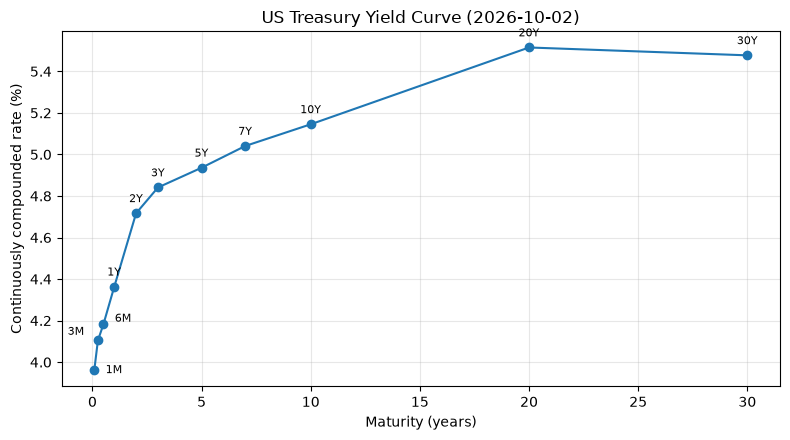

,yield_pct,maturity_years,yield_cc_pct
1M,4.04,0.083333,3.960525
3M,4.19,0.250000,4.104597
6M,4.27,0.500000,4.181350
1Y,4.46,1.000000,4.363404
2Y,4.83,2.000000,4.716980
3Y,4.96,3.000000,4.840914
5Y,5.06,5.000000,4.936143
7Y,5.17,7.000000,5.040790
10Y,5.28,10.000000,5.145328
20Y,5.67,20.000000,5.515084


In [50]:
latest_rates = df_treasury.iloc[-1]
maturity_years = {
    "1M": 1 / 12,
    "3M": 3 / 12,
    "6M": 6 / 12,
    "1Y": 1,
    "2Y": 2,
    "3Y": 3,
    "5Y": 5,
    "7Y": 7,
    "10Y": 10,
    "20Y": 20,
    "30Y": 30,
}

yield_curve = latest_rates.rename("yield_pct").to_frame()
yield_curve["maturity_years"] = yield_curve.index.map(maturity_years)
yield_curve = yield_curve.sort_values("maturity_years")
# Quoted yields are annually compounded. Continuous rate is r = ln(1 + z).
yield_curve["yield_cc_pct"] = np.log1p(yield_curve["yield_pct"] / 100) * 100

as_of = latest_rates.name.strftime("%Y-%m-%d")
label_offsets = {
    "1M": (14, -2),
    "3M": (-16, 4),
    "6M": (14, 2),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(yield_curve["maturity_years"], yield_curve["yield_cc_pct"], marker="o")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

yield_curve


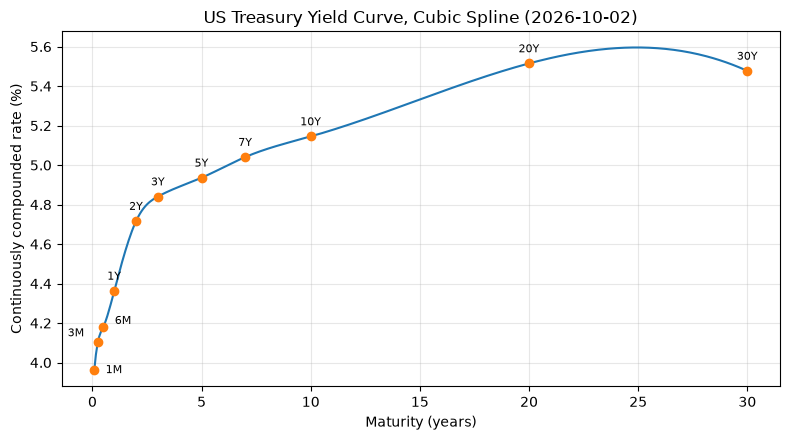

In [51]:
latest_rates = df_treasury.iloc[-1]
maturity_years = {
    "1M": 1 / 12,
    "3M": 3 / 12,
    "6M": 6 / 12,
    "1Y": 1,
    "2Y": 2,
    "3Y": 3,
    "5Y": 5,
    "7Y": 7,
    "10Y": 10,
    "20Y": 20,
    "30Y": 30,
}

yield_curve = latest_rates.rename("yield_pct").to_frame()
yield_curve["maturity_years"] = yield_curve.index.map(maturity_years)
yield_curve = yield_curve.sort_values("maturity_years")
yield_curve["yield_cc_pct"] = np.log1p(yield_curve["yield_pct"] / 100) * 100

tenors = yield_curve["maturity_years"].to_numpy()
tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
continuous_spline = CubicSpline(tenors, yield_curve["yield_cc_pct"].to_numpy())

as_of = latest_rates.name.strftime("%Y-%m-%d")
label_offsets = {
    "1M": (14, -2),
    "3M": (-16, 4),
    "6M": (14, 2),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tenor_grid, continuous_spline(tenor_grid))
ax.plot(tenors, yield_curve["yield_cc_pct"], marker="o", linestyle="none")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Cubic Spline ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


The Nelson-Siegel curve is fitted to the continuously compounded yields:

$$
y(\tau)=\beta_0+\beta_1\frac{1-e^{-\tau/\lambda}}{\tau/\lambda}+\beta_2\left(\frac{1-e^{-\tau/\lambda}}{\tau/\lambda}-e^{-\tau/\lambda}\right)
$$

where $\tau$ is maturity in years. $\beta_0$ is the long-run level, $\beta_1$ is how far the short end sits from that level, $\beta_2$ is the hump, and $\lambda$ sets how fast the curve settles. Those four numbers are fitted to the eleven quoted yields.

Unlike the straight-line and cubic-spline charts, this curve does not pass through every quote. It is one smooth function, so a bend such as the dip from 20 years to 30 years can sit a few basis points off the dots.

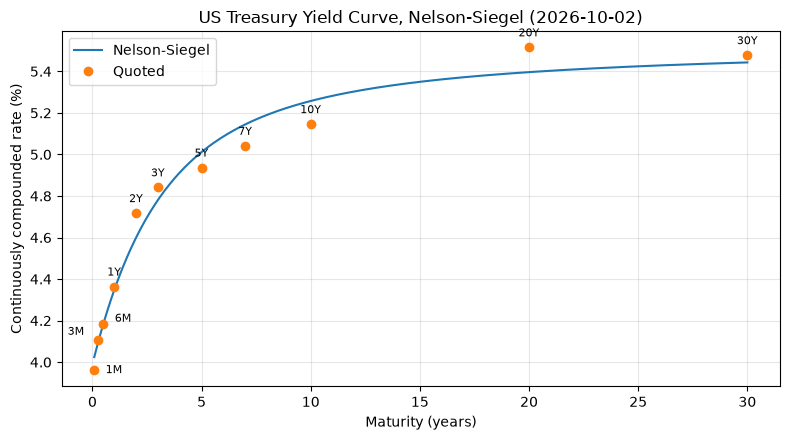

beta0 = 5.536  beta1 = -1.547  beta2 = 0.000  lambda = 1.810


In [52]:

def nelson_siegel(tau, beta0, beta1, beta2, lam):
    """Continuously compounded Nelson-Siegel yield at maturity tau (years)."""
    x = tau / lam
    exp_x = np.exp(-x)
    factor = np.where(np.abs(x) < 1e-8, 1.0, (1 - exp_x) / x)
    return beta0 + beta1 * factor + beta2 * (factor - exp_x)

latest_rates = df_treasury.iloc[-1]
maturity_years = {
    "1M": 1 / 12,
    "3M": 3 / 12,
    "6M": 6 / 12,
    "1Y": 1,
    "2Y": 2,
    "3Y": 3,
    "5Y": 5,
    "7Y": 7,
    "10Y": 10,
    "20Y": 20,
    "30Y": 30,
}

yield_curve = latest_rates.rename("yield_pct").to_frame()
yield_curve["maturity_years"] = yield_curve.index.map(maturity_years)
yield_curve = yield_curve.sort_values("maturity_years")
yield_curve["yield_cc_pct"] = np.log1p(yield_curve["yield_pct"] / 100) * 100

tenors = yield_curve["maturity_years"].to_numpy()
yields = yield_curve["yield_cc_pct"].to_numpy()
# beta0 ~ long rate, beta1 ~ short minus long, beta2 ~ hump, lam ~ decay in years
p0 = [yields[-1], yields[0] - yields[-1], 0.0, 2.0]
bounds = ([-5, -20, -20, 0.05], [20, 20, 20, 30])
beta0, beta1, beta2, lam = curve_fit(
    nelson_siegel, tenors, yields, p0=p0, bounds=bounds
)[0]

tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
fitted = nelson_siegel(tenor_grid, beta0, beta1, beta2, lam)

as_of = latest_rates.name.strftime("%Y-%m-%d")
label_offsets = {
    "1M": (14, -2),
    "3M": (-16, 4),
    "6M": (14, 2),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tenor_grid, fitted, label="Nelson-Siegel")
ax.plot(tenors, yields, marker="o", linestyle="none", label="Quoted")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Nelson-Siegel ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"beta0 = {beta0:.3f}  beta1 = {beta1:.3f}  beta2 = {beta2:.3f}  lambda = {lam:.3f}")

Svensson adds a second hump to Nelson-Siegel:

$$
y(\tau)=\beta_0+\beta_1\frac{1-e^{-\tau/\lambda_1}}{\tau/\lambda_1}+\beta_2\left(\frac{1-e^{-\tau/\lambda_1}}{\tau/\lambda_1}-e^{-\tau/\lambda_1}\right)+\beta_3\left(\frac{1-e^{-\tau/\lambda_2}}{\tau/\lambda_2}-e^{-\tau/\lambda_2}\right)
$$

$\beta_3$ and $\lambda_2$ are that extra hump and its maturity. The fit tries a few starting points and keeps the one that is not stuck on a bound. Like Nelson-Siegel, the curve is one smooth function, so it does not pass through every quote. The second hump lets it follow a bend such as 20 years to 30 years more closely.

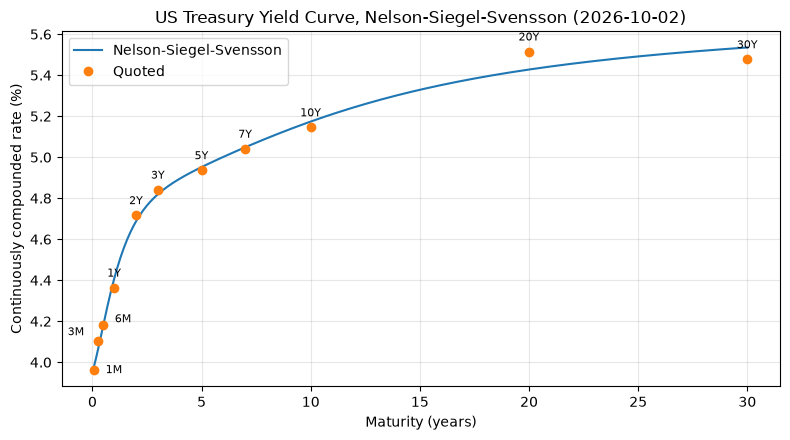

beta0 = 5.755  beta1 = -1.800  beta2 = -1.208  beta3 = -1.726  lambda1 = 0.480  lambda2 = 2.983


In [53]:
def nelson_siegel_svensson(tau, beta0, beta1, beta2, beta3, lam1, lam2):
    """Continuously compounded Nelson-Siegel-Svensson yield at maturity tau (years)."""
    def loadings(lam):
        x = tau / lam
        exp_x = np.exp(-x)
        level = np.where(np.abs(x) < 1e-8, 1.0, (1 - exp_x) / x)
        return level, level - exp_x

    slope, curve1 = loadings(lam1)
    _, curve2 = loadings(lam2)
    return beta0 + beta1 * slope + beta2 * curve1 + beta3 * curve2

latest_rates = df_treasury.iloc[-1]
maturity_years = {
    "1M": 1 / 12,
    "3M": 3 / 12,
    "6M": 6 / 12,
    "1Y": 1,
    "2Y": 2,
    "3Y": 3,
    "5Y": 5,
    "7Y": 7,
    "10Y": 10,
    "20Y": 20,
    "30Y": 30,
}

yield_curve = latest_rates.rename("yield_pct").to_frame()
yield_curve["maturity_years"] = yield_curve.index.map(maturity_years)
yield_curve = yield_curve.sort_values("maturity_years")
yield_curve["yield_cc_pct"] = np.log1p(yield_curve["yield_pct"] / 100) * 100

tenors = yield_curve["maturity_years"].to_numpy()
yields = yield_curve["yield_cc_pct"].to_numpy()

# Six parameters, so try a few starts and keep the best fit that is not stuck on a bound.
bounds = ([3, -10, -10, -10, 0.1, 1.0], [10, 10, 10, 10, 5, 30])
starts = [
    [yields[-1], yields[0] - yields[-1], 0.0, 0.0, 1.5, 8.0],
    [yields[-1], yields[0] - yields[-1], -1.0, -1.5, 0.5, 3.0],
    [yields[-1], yields[0] - yields[-1], -2.0, 2.0, 1.0, 10.0],
    [yields[-1], yields[0] - yields[-1], 2.0, -2.0, 2.0, 15.0],
]
lower, upper = np.array(bounds[0]), np.array(bounds[1])
best = None
for start in starts:
    fitted_params = curve_fit(
        nelson_siegel_svensson, tenors, yields, p0=start, bounds=bounds, maxfev=20000
    )[0]
    residual = nelson_siegel_svensson(tenors, *fitted_params) - yields
    sse = np.sum(residual**2)
    on_bound = np.any(np.isclose(fitted_params, lower) | np.isclose(fitted_params, upper))
    if best is None or (on_bound, sse) < best[0]:
        best = ((on_bound, sse), fitted_params)

beta0, beta1, beta2, beta3, lam1, lam2 = best[1]
tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
fitted = nelson_siegel_svensson(tenor_grid, beta0, beta1, beta2, beta3, lam1, lam2)

as_of = latest_rates.name.strftime("%Y-%m-%d")
label_offsets = {
    "1M": (14, -2),
    "3M": (-16, 4),
    "6M": (14, 2),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tenor_grid, fitted, label="Nelson-Siegel-Svensson")
ax.plot(tenors, yields, marker="o", linestyle="none", label="Quoted")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Nelson-Siegel-Svensson ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(
    f"beta0 = {beta0:.3f}  beta1 = {beta1:.3f}  beta2 = {beta2:.3f}  beta3 = {beta3:.3f}  "
    f"lambda1 = {lam1:.3f}  lambda2 = {lam2:.3f}"
)

The curve is a Matérn function whose length scale and noise are learned from the eleven quotes. A small noise term means it is not forced through every point. The shaded band is the 95% range. It stays tight where maturities are close together, and it widens in the gaps from 10 to 20 years and from 20 to 30 years, where the data say less about the yield in between.

The Gaussian process does not take arbitrage into account.

A discount curve is free of static arbitrage only if the discount factor falls as maturity gets longer. With continuous compounding that discount factor is $e^{-y(\tau)\tau}$, and it falls only when the instantaneous forward stays non-negative:

$$
f(\tau)=y(\tau)+\tau\,y'(\tau)\ge 0
$$

The fit never checks that. It only learns a smooth curve and a noise level from the eleven quotes. The shaded band includes many paths whose forwards would go negative.

On the latest quotes, the mean curve happens to stay clear of that: its lowest instantaneous forward is about 4%, at the short end, and the forward is still about 4.6% at 30 years. That is a property of this dataset, not a constraint in the model.

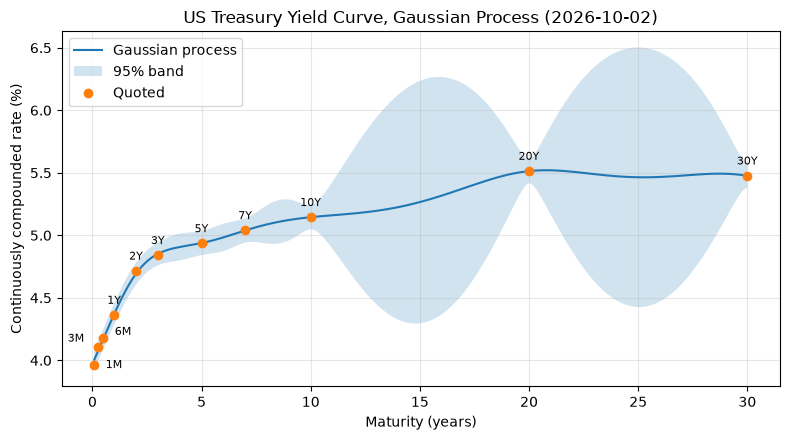

1.52**2 * Matern(length_scale=5.46, nu=2.5) + WhiteKernel(noise_level=0.00458)


In [55]:
latest_rates = df_treasury.iloc[-1]
maturity_years = {
    "1M": 1 / 12,
    "3M": 3 / 12,
    "6M": 6 / 12,
    "1Y": 1,
    "2Y": 2,
    "3Y": 3,
    "5Y": 5,
    "7Y": 7,
    "10Y": 10,
    "20Y": 20,
    "30Y": 30,
}

yield_curve = latest_rates.rename("yield_pct").to_frame()
yield_curve["maturity_years"] = yield_curve.index.map(maturity_years)
yield_curve = yield_curve.sort_values("maturity_years")
yield_curve["yield_cc_pct"] = np.log1p(yield_curve["yield_pct"] / 100) * 100

tenors = yield_curve["maturity_years"].to_numpy()
yields = yield_curve["yield_cc_pct"].to_numpy()

# Matérn kernel for a smooth curve, plus a little noise so the fit is not forced through every quote.
kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(
    length_scale=5.0, length_scale_bounds=(0.2, 50.0), nu=2.5
) + WhiteKernel(noise_level=0.01, noise_level_bounds=(1e-5, 0.1))
gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=8,
    normalize_y=True,
    random_state=0,
)
gp.fit(tenors.reshape(-1, 1), yields)

tenor_grid = np.linspace(tenors[0], tenors[-1], 400)
mean, std = gp.predict(tenor_grid.reshape(-1, 1), return_std=True)

as_of = latest_rates.name.strftime("%Y-%m-%d")
label_offsets = {
    "1M": (14, -2),
    "3M": (-16, 4),
    "6M": (14, 2),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tenor_grid, mean, label="Gaussian process")
ax.fill_between(
    tenor_grid,
    mean - 2 * std,
    mean + 2 * std,
    alpha=0.2,
    label="95% band",
)
ax.plot(tenors, yields, marker="o", linestyle="none", label="Quoted")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, Gaussian Process ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(gp.kernel_)

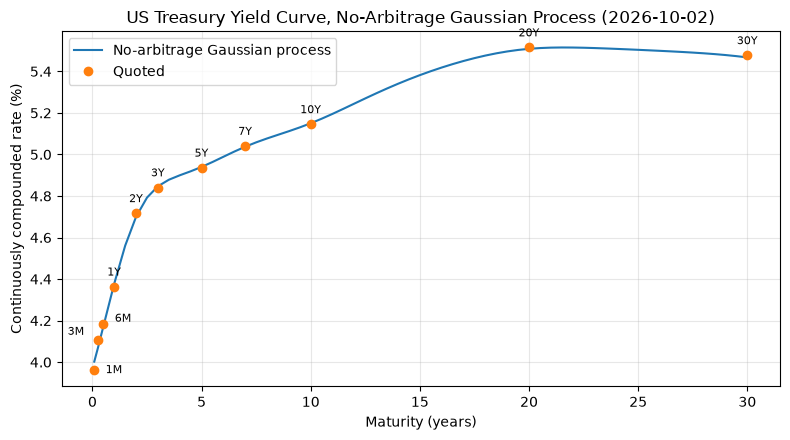

length scale = 2.0 years  minimum instantaneous forward = 3.97%


In [54]:
from scipy.optimize import minimize
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

def softplus(x):
    """Positive smooth map, so the instantaneous forward cannot go negative."""
    return np.log1p(np.exp(-np.abs(x))) + np.maximum(x, 0)

latest_rates = df_treasury.iloc[-1]
maturity_years = {
    "1M": 1 / 12,
    "3M": 3 / 12,
    "6M": 6 / 12,
    "1Y": 1,
    "2Y": 2,
    "3Y": 3,
    "5Y": 5,
    "7Y": 7,
    "10Y": 10,
    "20Y": 20,
    "30Y": 30,
}

yield_curve = latest_rates.rename("yield_pct").to_frame()
yield_curve["maturity_years"] = yield_curve.index.map(maturity_years)
yield_curve = yield_curve.sort_values("maturity_years")
yield_curve["yield_cc_pct"] = np.log1p(yield_curve["yield_pct"] / 100) * 100

tenors = yield_curve["maturity_years"].to_numpy()
yields = yield_curve["yield_cc_pct"].to_numpy()

# Latent curve g is a Gaussian process. The forward is softplus(g) > 0,
# and the zero rate is the average of that forward up to each maturity.
grid = np.unique(np.concatenate([np.linspace(0, tenors[-1], 61), tenors]))
obs_idx = np.searchsorted(grid, tenors)
sigma = 0.05  # yield noise, in percent

def fit_no_arb(length_scale):
    kernel = ConstantKernel(1.0) * Matern(length_scale=length_scale, nu=2.5)
    prior = kernel(grid.reshape(-1, 1))
    prior[np.diag_indices(len(grid))] += 1e-8
    weights_to_curve = np.linalg.cholesky(prior)

    def curve_from(weights):
        forward = softplus(np.mean(yields) + weights_to_curve @ weights)
        gaps = np.diff(grid)
        integral = np.concatenate(
            [[0.0], np.cumsum(0.5 * (forward[1:] + forward[:-1]) * gaps)]
        )
        zero = integral[1:] / grid[1:]
        return zero, forward

    def loss(weights):
        zero, _ = curve_from(weights)
        fitted = zero[obs_idx - 1]
        return np.sum((fitted - yields) ** 2) / sigma**2 + np.sum(weights**2)

    result = minimize(loss, np.zeros(len(grid)), method="L-BFGS-B")
    zero, forward = curve_from(result.x)
    return result.fun, zero, forward

best = None
for length_scale in (1.5, 2.0, 3.0, 5.0, 8.0):
    objective, zero, forward = fit_no_arb(length_scale)
    if best is None or objective < best[0]:
        best = (objective, length_scale, zero, forward)

_, length_scale, zero, forward = best
min_forward = forward.min()

as_of = latest_rates.name.strftime("%Y-%m-%d")
label_offsets = {
    "1M": (14, -2),
    "3M": (-16, 4),
    "6M": (14, 2),
}

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid[1:], zero, label="No-arbitrage Gaussian process")
ax.plot(tenors, yields, marker="o", linestyle="none", label="Quoted")
for maturity, row in yield_curve.iterrows():
    ax.annotate(
        maturity,
        (row["maturity_years"], row["yield_cc_pct"]),
        textcoords="offset points",
        xytext=label_offsets.get(maturity, (0, 8)),
        ha="center",
        fontsize=8,
    )
ax.set_title(f"US Treasury Yield Curve, No-Arbitrage Gaussian Process ({as_of})")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Continuously compounded rate (%)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(
    f"length scale = {length_scale:.1f} years  "
    f"minimum instantaneous forward = {min_forward:.2f}%"
)